# Bank distress & manipulation screener: Altman Z'' + Beneish M + ML layer

**What this notebook does**

1. Loads the six-bank panel exported from your research workbook (`data/bank_panel.csv`).
2. Computes **Altman Z''** (bank-adapted, emerging-market) and **Beneish M** (bank-mapped) with the exact
   formulas, switches and cut-offs from the workbook's `Parameters` tab, and checks them against the workbook's `Ratios` tab.
3. Fits the **ML layer**: an unsupervised Isolation-Forest anomaly model and a small supervised early-warning model.
4. Validates every signal against the Yes Bank event (RBI moratorium, 5 Mar 2020).
5. Shows how the website back-end scores a new bank.

**Important:** Z'' and M are closed-form formulas, so they are computed *exactly*, not learned. A learned model would only approximate them.
The ML sits on top and answers a different question: *does this bank-year look unusual, and does it resemble the run-up to a known distress event?*

**Data caveat:** a large share of the inputs in the workbook are mechanical estimates (see `n_estimated_fields`, `Estimate_Log`), and FY2025-26 values are projections.
Results show the method working; they are not audited findings.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from bank_risk.scoring import Params, score_panel
from bank_risk.ml import RiskModels, load_events, make_labels, event_validation
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

raw = pd.read_csv(ROOT / "data" / "bank_panel.csv")
events = load_events(ROOT / "data" / "events.csv")
print(raw.shape, "| banks:", raw.bank.unique().tolist())
raw[["bank","fy","total_assets","net_profit","market_cap","gnpa","crar","n_estimated_fields"]].head(10)

(54, 36) | banks: ['HDFC Bank', 'ICICI Bank', 'Axis Bank', 'Yes Bank', 'IDFC First Bank', 'State Bank of India']


,bank,fy,total_assets,net_profit,market_cap,gnpa,crar,n_estimated_fields
0,HDFC Bank,FY2018,1063934.0,17487.0,NaN,0.0124,0.1955,9
1,HDFC Bank,FY2019,1244541.0,21078.0,574062.58,0.0124,0.1955,10
2,HDFC Bank,FY2020,1530511.0,26257.0,674453.50,0.0124,0.1955,10
3,HDFC Bank,FY2021,1746871.0,31117.0,746719.01,0.0124,0.1955,10
4,HDFC Bank,FY2022,2068535.0,36961.0,792306.90,0.0124,0.1955,6
5,HDFC Bank,FY2023,2466081.0,44109.0,874220.88,0.0124,0.1955,6
6,HDFC Bank,FY2024,3617623.0,60812.0,1065395.32,0.0124,0.1955,4
7,HDFC Bank,FY2025,3910199.0,67347.0,1353844.80,0.0133,0.1955,3
8,HDFC Bank,FY2026,4364886.0,74671.0,1092027.94,0.0115,0.1971,1
9,ICICI Bank,FY2018,879189.0,6777.0,NaN,0.0360,0.1842,8


## 1. Exact scores: Altman Z'' and Beneish M

In [2]:
p = Params()          # workbook defaults: X1 weight 6.56, +3.25 EM constant, cut-offs 5.85 / 4.35, M cut-off -1.78
scored = score_panel(raw, p)
cols = ["bank","fy","x1_liquidity","x2_reserves_ta","x3_profit_ta","x4_mcap_liab","z_em","z_zone","m_score","m_flag_a","joint_signal"]
scored[cols].round(3).head(18)

,bank,fy,x1_liquidity,x2_reserves_ta,x3_profit_ta,x4_mcap_liab,z_em,z_zone,m_score,m_flag_a,joint_signal
0,Axis Bank,FY2018,0.074,0.091,0.000,NaN,NaN,n/a,NaN,n/a,n/a
1,Axis Bank,FY2019,0.070,0.083,0.009,0.232,4.282,Distress,-2.498,OK,Z only
2,Axis Bank,FY2020,0.070,0.092,0.005,0.246,4.303,Distress,-2.530,OK,Z only
3,Axis Bank,FY2021,0.102,0.102,0.009,0.223,4.546,Grey,-2.514,OK,Neither
4,Axis Bank,FY2022,0.126,0.097,0.015,0.215,4.720,Grey,-2.522,OK,Neither
5,Axis Bank,FY2023,0.114,0.095,0.013,0.215,4.617,Grey,-2.397,OK,Neither
6,Axis Bank,FY2024,0.128,0.102,0.022,0.236,4.817,Grey,-2.322,OK,Neither
7,Axis Bank,FY2025,0.148,0.111,0.021,0.230,4.970,Grey,-2.466,OK,Neither
8,Axis Bank,FY2026,0.148,0.111,0.021,0.212,4.951,Grey,-2.410,OK,Neither
9,HDFC Bank,FY2018,0.143,0.099,0.025,NaN,NaN,n/a,NaN,n/a,n/a


### Parity check against the workbook's own `Ratios` tab

In [3]:
wb = pd.read_csv(ROOT/"data"/"workbook_ratios.csv", keep_default_na=False, na_values=[""]).rename(columns={"Bank":"bank","FY":"fy"})
m = scored.merge(wb, on=["bank","fy"])
pairs = {"Z''-EM (+3.25)":"z_em", "Beneish M-score":"m_score", "DSRI":"dsri", "GMI":"gmi", "AQI":"aqi",
         "SGI":"sgi", "DEPI":"depi", "SGAI":"sgai", "LVGI":"lvgi", "TATA":"tata"}
rows = []
for w, c in pairs.items():
    a, b = pd.to_numeric(m[c], errors="coerce"), pd.to_numeric(m[w], errors="coerce")
    ok = a.notna() & b.notna()
    rows.append({"metric": w, "rows compared": int(ok.sum()), "max abs diff": float((a[ok]-b[ok]).abs().max())})
pd.DataFrame(rows)

,metric,rows compared,max abs diff
0,Z''-EM (+3.25),47,5.329071e-15
1,Beneish M-score,48,4.884981e-15
2,DSRI,48,4.662937e-15
3,GMI,48,5.107026e-15
4,AQI,48,4.662937e-15
5,SGI,48,5.107026e-15
6,DEPI,48,4.662937e-15
7,SGAI,48,4.884981e-15
8,LVGI,48,5.107026e-15
9,TATA,54,4.440892e-16


## 2. What the scores say

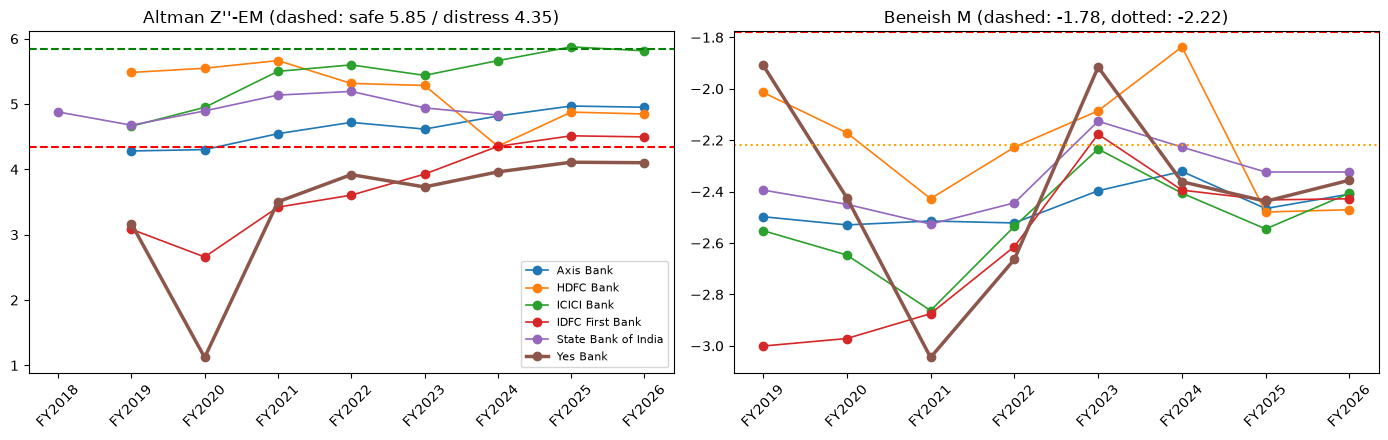

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for bank, g in scored.groupby("bank"):
    ax[0].plot(g.fy, g.z_em, marker="o", label=bank, lw=2.5 if bank=="Yes Bank" else 1.2)
    ax[1].plot(g.fy, g.m_score, marker="o", label=bank, lw=2.5 if bank=="Yes Bank" else 1.2)
ax[0].axhline(p.z_safe, ls="--", c="g"); ax[0].axhline(p.z_distress, ls="--", c="r")
ax[0].set_title("Altman Z''-EM (dashed: safe 5.85 / distress 4.35)")
ax[1].axhline(p.m_cutoff_a, ls="--", c="r"); ax[1].axhline(p.m_cutoff_b, ls=":", c="orange")
ax[1].set_title("Beneish M (dashed: -1.78, dotted: -2.22)")
for a in ax: a.tick_params(axis="x", rotation=45)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [5]:
print("Z'' zones:", scored.z_zone.value_counts().to_dict())
print("M flags @ -1.78:", scored.m_flag_a.value_counts().to_dict(), "| @ -2.22:", scored.m_flag_b.value_counts().to_dict())
print("\nLowest Z''-EM bank-years:"); print(scored.nsmallest(5, "z_em")[["bank","fy","z_em","z_zone","gnpa","crar"]].round(3).to_string(index=False))
print("\nHighest M bank-years:");   print(scored.nlargest(5, "m_score")[["bank","fy","m_score","m_flag_b"]].round(3).to_string(index=False))

Z'' zones: {'Grey': 31, 'Distress': 15, 'n/a': 7, 'Safe': 1}
M flags @ -1.78: {'OK': 48, 'n/a': 6} | @ -2.22: {'OK': 40, 'Flag': 8, 'n/a': 6}

Lowest Z''-EM bank-years:
           bank     fy  z_em   z_zone  gnpa  crar
       Yes Bank FY2020 1.121 Distress 0.168 0.085
IDFC First Bank FY2020 2.660 Distress 0.026 0.168
IDFC First Bank FY2019 3.084 Distress 0.024 0.168
       Yes Bank FY2019 3.170 Distress 0.032 0.165
IDFC First Bank FY2021 3.422 Distress 0.026 0.168

Highest M bank-years:
     bank     fy  m_score m_flag_b
HDFC Bank FY2024   -1.837     Flag
 Yes Bank FY2019   -1.908     Flag
 Yes Bank FY2023   -1.916     Flag
HDFC Bank FY2019   -2.014     Flag
HDFC Bank FY2023   -2.086     Flag


**Reading this honestly**

* Z''-EM puts Yes Bank FY2020 (the moratorium year) far below every other bank-year, but it also labels *Axis* and *IDFC First* as "Distress" in some years: the zone cut-offs are not calibrated for banks, the *ranking* is more informative than the label.
* Beneish M never crosses -1.78 for any bank-year. The -2.22 cut-off flags some rows, mostly false positives. M was built for non-financial firms, so on banks it is a weak signal.
* Merger years (HDFC Bank FY2024, IDFC First FY2019) distort the M indices; they are tagged as structural breaks.

## 3. ML layer

In [6]:
models = RiskModels.fit(scored, events, horizon=1)
pred = models.predict(scored, events)
labels = make_labels(scored, events, horizon=1)
print("labelled-positive rows:", pred.loc[labels==1, ["bank","fy"]].values.tolist())
print("\nearly-warning model:", models.report["early_warning"]["note"])
pred[["bank","fy","z_em","m_score","anomaly_percentile","early_warning_prob","structural_break","risk_tier"]].round(3).query("bank in ['Yes Bank','IDFC First Bank']")

labelled-positive rows: [['Yes Bank', 'FY2019'], ['Yes Bank', 'FY2020']]

early-warning model: In-sample only. With 1 distressed bank(s) a leave-one-bank-out test removes every positive, so no out-of-sample performance can be reported. Add more labelled events (data/events.csv) and retrain before relying on this output.


,bank,fy,z_em,m_score,anomaly_percentile,early_warning_prob,structural_break,risk_tier
27,IDFC First Bank,FY2018,NaN,NaN,5.6,0.042,False,Insufficient data
28,IDFC First Bank,FY2019,3.084,-3.001,94.4,0.029,True,Watch
29,IDFC First Bank,FY2020,2.660,-2.971,96.3,0.060,False,High
30,IDFC First Bank,FY2021,3.422,-2.875,83.3,0.025,False,Watch
31,IDFC First Bank,FY2022,3.606,-2.614,57.4,0.069,False,Watch
32,IDFC First Bank,FY2023,3.928,-2.177,42.6,0.257,False,Watch
33,IDFC First Bank,FY2024,4.352,-2.394,14.8,0.054,False,Low
34,IDFC First Bank,FY2025,4.514,-2.432,13.0,0.049,False,Low
35,IDFC First Bank,FY2026,4.497,-2.428,3.7,0.048,False,Low
45,Yes Bank,FY2018,NaN,NaN,29.6,0.032,False,Insufficient data


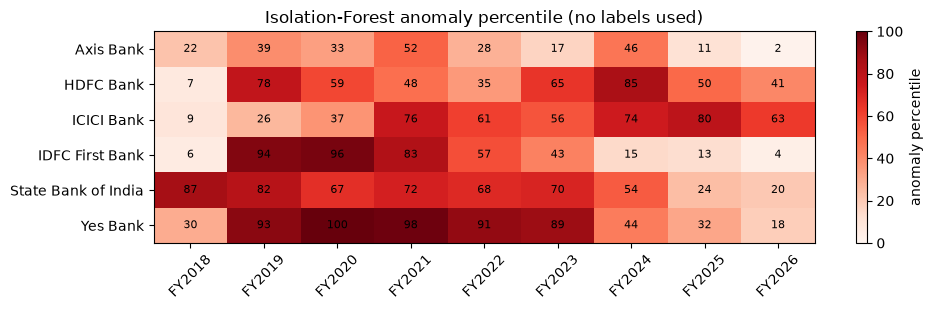

In [7]:
piv = pred.pivot(index="bank", columns="fy", values="anomaly_percentile")
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(piv.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=45)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, "" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="anomaly percentile"); ax.set_title("Isolation-Forest anomaly percentile (no labels used)"); plt.tight_layout(); plt.show()

## 4. Validation against the Yes Bank event

In [8]:
val = event_validation(pred, labels)
print("AUC (higher = riskier):", {k: round(v, 3) for k, v in val.attrs["auc"].items()})
val.round(3)

AUC (higher = riskier): {"-Z''-EM": 0.978, 'M-score': 0.761, 'Anomaly score': 0.971}


,signal,TP,FP,FN,TN,sensitivity,specificity,n_scored
0,Z'' zone = Distress,2,13,0,32,1.0,0.711,47
1,M flag (cut-off -1.78),0,0,2,46,0.0,1.000,48
2,M flag (cut-off -2.22),1,7,1,39,0.5,0.848,48
3,Z + M both flag,0,0,2,44,0.0,1.000,46
4,Anomaly pct >= 90,2,4,0,48,1.0,0.923,54
5,Tier High (rules + anomaly only),1,2,1,44,0.5,0.957,48
6,Tier High or Watch (rules + anomaly only),2,18,0,28,1.0,0.609,48
7,Tier High (incl. in-sample early-warning),2,2,0,44,1.0,0.957,48


Only **2 labelled rows** (Yes Bank FY2019 and FY2020) exist, so sensitivity/specificity are indicative at best.
The row "Tier High (incl. in-sample early-warning)" is *circular*: that model was trained on those same two rows. Use the "rules + anomaly only" rows for an honest read.

## 5. Sensitivity to the bank-adaptation switches

In [9]:
rows = []
for x3 in (1, 2):
    for recv in (1, 2):
        for cut in (1, 2):
            q = Params(x3_definition=x3, receivables_proxy=recv, joint_cutoff=cut)
            s = score_panel(raw, q)
            yb = s[(s.bank=="Yes Bank") & (s.fy=="FY2020")].iloc[0]
            rows.append({"X3 def": x3, "recv proxy": recv, "M cut-off": cut,
                         "Yes FY20 Z''-EM": round(yb.z_em, 2), "Yes FY20 M": None if pd.isna(yb.m_score) else round(yb.m_score, 2),
                         "rows Z distress": int((s.z_zone=="Distress").sum()),
                         "rows joint Z+M": int((s.joint_signal=="Z + M both flag").sum())})
pd.DataFrame(rows)

,X3 def,recv proxy,M cut-off,Yes FY20 Z''-EM,Yes FY20 M,rows Z distress,rows joint Z+M
0,1,1,1,1.12,NaN,15,0
1,1,1,2,1.12,NaN,15,0
2,1,2,1,1.12,-2.42,15,0
3,1,2,2,1.12,-2.42,15,3
4,2,1,1,1.62,NaN,11,0
5,2,1,2,1.62,NaN,11,0
6,2,2,1,1.62,-2.42,11,0
7,2,2,2,1.62,-2.42,11,3


`receivables_proxy = 1` needs interest-receivable data that is not loaded for any bank, so those rows show blank M-scores. That is the model refusing to guess.

## 6. Scoring a new bank (what the website will do)

In [10]:
from bank_risk.schema import REQUIRED_MINIMUM
new = raw[(raw.bank=="Yes Bank") & raw.fy.isin(["FY2019","FY2020","FY2021"])][REQUIRED_MINIMUM]   # minimal form fields only
q = Params(neutral_fill=True)
out = models.predict(score_panel(new, q), events)
out[["bank","fy","z_em","z_zone","m_score","anomaly_percentile","risk_tier","input_notes"]].round(3)

,bank,fy,z_em,z_zone,m_score,anomaly_percentile,risk_tier,input_notes
0,Yes Bank,FY2019,3.173,Distress,-2.156,61.1,Watch,borrowings+other_liabilities = total_liabiliti...
1,Yes Bank,FY2020,1.125,Distress,-1.630,94.4,High,borrowings+other_liabilities = total_liabiliti...
2,Yes Bank,FY2021,3.566,Distress,-3.824,92.6,Watch,borrowings+other_liabilities = total_liabiliti...


With only the minimum columns, several inputs are *derived* (listed in `input_notes`) and missing Beneish indices become neutral, so the M-score is approximate.
The API warns about this. The full column set gives results identical to section 1.

## 7. Save the trained model

In [11]:
from bank_risk.pipeline import MODEL_PATH
MODEL_PATH.parent.mkdir(exist_ok=True); models.save(MODEL_PATH)
print("saved ->", MODEL_PATH)

saved -> D:\Placements\SEMVII\BFSI\bank_risk_ml\bank_risk_ml\models\risk_models.joblib
